# DISCOVERSE：找回的学习策略训练与闭环诊断

旧设备档案中已有500条专家演示、44439帧数据及三种学习策略的训练记录。本篇补齐训练曲线、闭环结果、失败录像与实际原生部署适配器。

ACT［动作分块变换器］训练1000轮，约8小时55分钟，随后未见种子评估0/10；扩散策略训练5000次更新，固定四种子评估0/4；π0.5［视觉语言动作模型］训练专家头500次更新，固定四种子评估0/4。三个结果来自各自的原实验条件，逐项呈现。专家采集成功率另见任务入口。


In [1]:
from pathlib import Path
import json, os, sys
from IPython.display import display, Markdown, Image, HTML
TOPIC = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "code/amd_benchmarks").is_dir())
E = TOPIC / "notebooks/results/discoverse-history"
def load(name):
    return json.loads((E / name).read_text())
def rows(name):
    out=[]
    for line in (E/name).read_text().splitlines():
        try: out.append(json.loads(line))
        except ValueError: pass
    return out
coverage=load("expert-coverage.json")
print({"专家演示数":coverage["episodes_found"], "完整夹爪阶段":coverage["episodes_with_complete_gripper_phases"], "总帧数":44439})


{'专家演示数': 500, '完整夹爪阶段': 500, '总帧数': 44439}


## 训练和评估分别记录

ACT［动作分块变换器］的1000轮由实际训练日志确认，最终日志保存最佳验证损失及检查点目录；扩散策略指标到第5000次更新；π0.5［视觉语言动作模型］记录已保存检查点、430098464个可训练参数和约11.13 GiB［二进制吉字节］内存峰值。三者都已有闭环评估，不将离线损失当作成功率。


In [2]:
records=[("动作分块策略",load("act-evaluation.json")),("扩散策略",load("diffusion-evaluation.json")),("视觉语言动作策略专家头",load("pi05-evaluation.json"))]
display(Markdown("|策略|训练量|闭环成功|\n|---|---|---|\n"+"\n".join(f"|{label}|{budget}|{d['successes']}/{d['episodes']}|" for (label,d),budget in zip(records,["1000轮","5000次更新","500次更新"]))))
print("动作分块策略：",load("act-epochs.json")["training_finished"])
print("视觉语言动作策略：",{k:load("pi05-training.json")[k] for k in ["checkpoint_saved","steps","dataset_frames","dataset_episodes","trainable_parameters","memory_peak_gib"]})


|策略|训练量|闭环成功|
|---|---|---|
|动作分块策略|1000轮|0/10|
|扩散策略|5000次更新|0/4|
|视觉语言动作策略专家头|500次更新|0/4|

动作分块策略： True
视觉语言动作策略： {'checkpoint_saved': True, 'steps': 500, 'dataset_frames': 44439, 'dataset_episodes': 500, 'trainable_parameters': 430098464, 'memory_peak_gib': 11.130908966064453}


## 保存的完整训练曲线

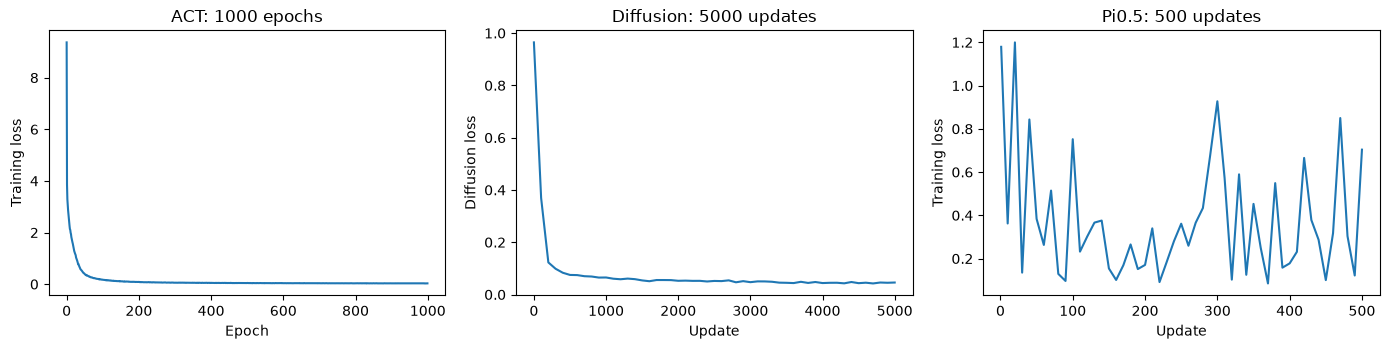

In [3]:
import matplotlib.pyplot as plt
act=load("act-epochs.json")
dp=rows("diffusion-metrics.jsonl")
pi=[r for r in rows("pi05-metrics.jsonl") if r.get("event")=="train"]
assert len(act["train_loss"])==1000 and dp[-1]["step"]==5000 and pi[-1]["step"]==500
fig,ax=plt.subplots(1,3,figsize=(14,3.6))
ax[0].plot(range(1000),act["train_loss"]);ax[0].set(title="ACT: 1000 epochs",xlabel="Epoch",ylabel="Training loss")
ax[1].plot([r["step"] for r in dp],[r["avg_diffusion_loss"] for r in dp]);ax[1].set(title="Diffusion: 5000 updates",xlabel="Update",ylabel="Diffusion loss")
ax[2].plot([r["step"] for r in pi],[r["loss"] for r in pi]);ax[2].set(title="Pi0.5: 500 updates",xlabel="Update",ylabel="Training loss")
fig.tight_layout();display(fig);plt.close(fig)


## 逐回合结果与失败视频

下方录像从原始评估目录复制，完整解码通过。每个评估的全部随机种子、步数和原始双视角路径保存在对应结果文件；相同种子在不同模型实验中的动作调度和接口条件仍以原始记录为准。


### 动作分块策略

|种子|成功|步数|
|---|---|---|
|1000|False|300|
|1001|False|300|
|1002|False|300|
|1003|False|300|
|1004|False|300|
|1005|False|300|
|1006|False|300|
|1007|False|300|
|1008|False|300|
|1009|False|300|

### 扩散策略

|种子|成功|步数|
|---|---|---|
|0|False|304|
|1|False|304|
|1000|False|304|
|1001|False|304|

### 视觉语言动作策略专家头

|种子|成功|步数|
|---|---|---|
|0|False|300|
|1|False|300|
|1000|False|300|
|1001|False|300|

动作分块策略：未见种子失败

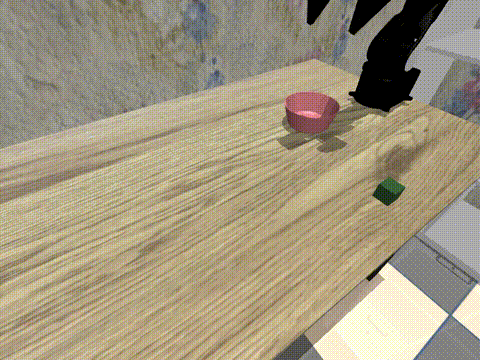

视觉语言动作策略：固定种子失败

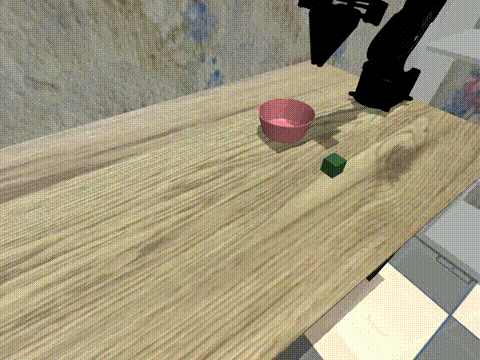

In [4]:
for label,d in records:
    display(Markdown("### "+label))
    display(Markdown("|种子|成功|步数|\n|---|---|---|\n"+"\n".join(f"|{r['seed']}|{r['success']}|{r['steps']}|" for r in d["results"])))
for label,tag in [("动作分块策略：未见种子失败","act"),("视觉语言动作策略：固定种子失败","pi05")]:
    display(Markdown(label));display(Image(filename=str(E/(tag+"-heldout-failure.gif"))))
    video_path = E/(tag+"-heldout-failure.mp4")
    compatible = video_path.with_name(video_path.stem + ".browser.mp4")
    relative=os.path.relpath(compatible if compatible.is_file() else video_path,Path.cwd())
    display(HTML(f'<video controls preload="metadata" width="640" src="{relative}"></video>'))


## 使用真实原生适配器复查

课程现附原生动作分块策略部署脚本 `code/discoverse_pipeline/eval_act_place_block.py`，提供相机颜色顺序、归一化统计、动作拼接、物理步数和逐回合录像接口。它读取原生策略检查点，不能直接读取另一篇 LeRobot 训练命令生成的权重。

若要复查此旧实验，设置 `AMD_REPRO_STAGE=discoverse-native-evaluate`，并设置 `EXPERIMENT_PYTHON`、`DISCOVERSE_NATIVE_ROOT`、`DISCOVERSE_NATIVE_CHECKPOINT`、`DISCOVERSE_NATIVE_STATS`、`DISCOVERSE_EVAL_ROOT`。将输出指向新的外置实验目录。下方显式参数对应旧实验10个未见种子、20赫兹和每回合300步。


In [5]:
import subprocess
if os.environ.get("AMD_REPRO_STAGE")=="discoverse-native-evaluate":
    required=["EXPERIMENT_PYTHON","DISCOVERSE_NATIVE_ROOT","DISCOVERSE_NATIVE_CHECKPOINT","DISCOVERSE_NATIVE_STATS","DISCOVERSE_EVAL_ROOT"]
    for key in required: assert os.environ.get(key),key
    command=[os.environ["EXPERIMENT_PYTHON"],str(TOPIC/"code/discoverse_pipeline/eval_act_place_block.py"),
             "--repo-root",os.environ["DISCOVERSE_NATIVE_ROOT"],"--checkpoint",os.environ["DISCOVERSE_NATIVE_CHECKPOINT"],
             "--stats",os.environ["DISCOVERSE_NATIVE_STATS"],"--output-dir",os.environ["DISCOVERSE_EVAL_ROOT"],
             "--max-steps","300","--control-fps","20","--image-color-order","bgr","--temporal-agg", "--seeds",*[str(s) for s in range(1000,1010)]]
    subprocess.run(command,check=True)
else:
    print("本篇显示已执行的历史训练和闭环结果；未启动新的重复评估。")


本篇显示已执行的历史训练和闭环结果；未启动新的重复评估。


## 还需要补齐什么

1. 另一篇通用 LeRobot 数据转换与训练路线尚缺与该权重格式匹配的完整部署适配器；其原伪代码已明确标为接口说明。
2. 这三种旧学习策略尚未获得该任务的闭环成功，后续要围绕相机颜色、动作／观测对齐、动作连续性及抓放阶段实际排查，并用同种子完整复评记录修复效果。
3. 原生与通用训练路线需要分别固定依赖、数据与归一化统计，避免跨格式加载。原始来源和文件内容指纹见 `notebooks/results/discoverse-history/sources.json`。


## 直接播放历史训练权重的闭环评估

以下两个完整失败回合分别来自已记录的动作分块策略和视觉语言动作策略，均保留原有失败结果与条件。

In [6]:
from pathlib import Path
from IPython.display import Video, display
_VIDEO_TOPIC = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "code/amd_benchmarks").is_dir())
display(Video(filename=str(_VIDEO_TOPIC / 'notebooks/results/discoverse-history/act-heldout-failure.mp4'), embed=True, width=640))


In [7]:
from pathlib import Path
from IPython.display import Video, display
_VIDEO_TOPIC = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "code/amd_benchmarks").is_dir())
display(Video(filename=str(_VIDEO_TOPIC / 'notebooks/results/discoverse-history/pi05-heldout-failure.browser.mp4'), embed=True, width=640))


## 原工程的完整动作分块训练实现

下面直接展开原工程 `policies/act/policy_train.py`：模型与优化器构建、数据加载、训练／验证、最佳权重与定期保存。源码从已完成的公开归档按完整指纹恢复；用于理解与复现原工程训练接口。历史闭环成绩和视频仍按前文的独立配方记录，不能混用。

完整运行前，设置 `DISCOVERSE_SOURCE_ROOT` 为已恢复的原工程目录、选择其既有训练环境，并配置原工程任务参数；默认仅阅读，不启动训练。

In [8]:
RUN_FULL = os.environ.get("AMD_RUN_FULL", "0") == "1"
if RUN_FULL:
    _discoverse_source = Path(os.environ["DISCOVERSE_SOURCE_ROOT"]).resolve()
    assert (_discoverse_source / "policies/act").is_dir()
    sys.path.insert(0, str(_discoverse_source))


In [9]:
if RUN_FULL:
    import argparse


In [10]:
if RUN_FULL:
    import logging


In [11]:
if RUN_FULL:
    import os


In [12]:
if RUN_FULL:
    import pickle


In [13]:
if RUN_FULL:
    import shutil


In [14]:
if RUN_FULL:
    import time


In [15]:
if RUN_FULL:
    from copy import deepcopy


In [16]:
if RUN_FULL:
    import matplotlib.pyplot as plt


In [17]:
if RUN_FULL:
    import numpy as np


In [18]:
if RUN_FULL:
    import torch


In [19]:
if RUN_FULL:
    from tqdm import tqdm


In [20]:
if RUN_FULL:
    from configurations.task_configs.config_tools.basic_configer import (
        basic_parser,
        get_all_config,
    )


In [21]:
if RUN_FULL:
    from policies.common.maker import make_policy


In [22]:
if RUN_FULL:
    from utils.utils import (
        GPUer,
        LoadDataConfig,
        compute_dict_mean,
        detach_dict,
        load_data,
        set_seed,
    )


In [23]:
if RUN_FULL:
    logging.basicConfig(level=logging.INFO)


In [24]:
if RUN_FULL:
    logger = logging.getLogger(__name__)


In [25]:
if RUN_FULL:
    def main(args: dict):
        # get all config
        all_config = get_all_config(args, "train")
        ckpt_dir = all_config["ckpt_dir"]
        stats_path = all_config["stats_path"]
        gpu_threshold = all_config.get("gpu_threshold", 10)

        # 加载数据及统计信息
        train_dataloader, val_dataloader, stats = load_data(
            LoadDataConfig(
                **all_config["load_data"],
                camera_names=all_config["camera_names"],
                chunk_sizes={"action": all_config["policy_config"]["chunk_size"]},
            )
        )
        # 创建保存路径
        os.makedirs(ckpt_dir, exist_ok=True)
        stats_dir = os.path.dirname(stats_path)
        os.makedirs(stats_dir, exist_ok=True)
        # 复制配置文件到stats_dir
        shutil.copy(all_config["config_file_sys_path"], stats_dir)
        # 保存统计数据
        stats_path = (
            os.path.join(ckpt_dir, "dataset_stats.pkl") if stats_path == "" else stats_path
        )
        print(f"Saving stats into {stats_path}...")
        with open(stats_path, "wb") as f:
            pickle.dump(stats, f)
        # 保存关键信息（must pop functions)
        key_info_path = os.path.join(stats_dir, "key_info.pkl")
        print(f"Saving key info into {key_info_path}...")
        all_config_cp = deepcopy(all_config)
        all_config_cp["policy_config"].pop("policy_maker")
        all_config_cp["environments"].pop("environment_maker")
        all_config_cp["load_data"].pop("augmentors")
        key_info = {
            "init_info": {
                "init_joint": all_config_cp["start_joint"],
                "init_action": all_config_cp["start_action"],
            },
            "all_config": all_config_cp,
        }
        with open(key_info_path, "wb") as f:
            pickle.dump(key_info, f)
        # wait for free GPU
        target_gpus = os.environ.get("CUDA_VISIBLE_DEVICES", "")
        target_gpus = target_gpus.split(",")
        target_gpus = [int(gpu) for gpu in target_gpus if gpu != ""]
        waiting_time = 60
        while True:
            free_gpus, gpus_num, gpu_utilizations = GPUer.check_all_gpus_idle(gpu_threshold)
            if len(free_gpus) > 0:
                if len(target_gpus) > 0:
                    not_free_ids = []
                    for index, target_gpu in enumerate(target_gpus):
                        if target_gpu >= gpus_num:
                            raise ValueError(
                                f"Target GPU id (from 0) {target_gpu} is not valid, only {gpus_num} gpus available"
                            )
                        elif target_gpu not in free_gpus:
                            not_free_ids.append(index)
                    if len(not_free_ids) != 0:
                        print(
                            f"Target GPU {target_gpus[not_free_ids]} is not free ({gpu_utilizations[not_free_ids]}), waiting for {waiting_time} senconds..."
                        )
                        time.sleep(waiting_time)
                        continue
                else:
                    free_gpu = free_gpus[0]
                    os.environ["CUDA_VISIBLE_DEVICES"] = str(free_gpu)
                    print(f"Using GPU {free_gpu}")
                    target_gpus = [int(free_gpu)]
                break
            else:
                print(f"No free GPU, waiting for {waiting_time} senconds...")
                time.sleep(waiting_time)
        print(f"Using GPU: {target_gpus}")
        all_config["target_gpus"] = target_gpus
        # train policy
        set_seed(all_config["seed"])
        best_ckpt_info = train_bc(train_dataloader, val_dataloader, all_config)
        best_epoch, min_val_loss, best_state_dict = best_ckpt_info
        print(f"Best ckpt, val loss {min_val_loss:.6f} @ epoch{best_epoch}")


In [26]:
if RUN_FULL:
    def make_optimizer(policy):
        if hasattr(policy, "configure_optimizers"):
            optimizer = policy.configure_optimizers()
        else:
            # TODO: 默认使用Adam优化器
            print("Warning: Using default optimizer")
        return optimizer


In [27]:
if RUN_FULL:
    def forward_pass(data: torch.Tensor, policy):
        image_data, qpos_data, action_data, is_pad = data
        image_data, qpos_data, action_data, is_pad = (
            image_data.cuda(),
            qpos_data.cuda(),
            action_data.cuda(),
            is_pad.cuda(),
        )
        # print("image_data.shape:", image_data.shape)
        return policy(qpos_data, image_data, action_data, is_pad)  # TODO remove None


In [28]:
if RUN_FULL:
    def get_epoch_base(pretrain_path, epoch_base):
        if pretrain_path == "":
            epoch_base = 0
        elif isinstance(epoch_base, str) and epoch_base.lstrip("-").isdigit():
            epoch_base = int(epoch_base)
        elif epoch_base == "AUTO":
            if (
                pretrain_path in ["best", "last"]
                or "best" in pretrain_path
                or "last" in pretrain_path
            ):
                epoch_base = 0
            else:
                try:
                    epoch_base = int(pretrain_path.split("_")[-3])
                except:
                    try:
                        epoch_base = int(pretrain_path.split("_")[-2])
                    except:
                        raise ValueError(
                            f"Invalid pretrain_ckpt_path to auto get epoch bias: {pretrain_path}"
                        )
        return epoch_base


In [29]:
if RUN_FULL:
    def train_bc(train_dataloader, val_dataloader, config):
        num_epochs = config["num_epochs"]
        ckpt_dir = config["ckpt_dir"]
        seed = config["seed"]
        policy_config = config["policy_config"]
        stats_dir = os.path.dirname(config["stats_path"])
        eval_every = 3.14 if config["eval_every"] == 0 else config["eval_every"]
        parallel = config["parallel"]
        if config["eval_every"] != 0:
            from policy_evaluate import eval_bc

        # make policy
        pretrain_path = config["pretrain_ckpt_path"]
        policy_config["ckpt_path"] = pretrain_path
        policy = make_policy(policy_config, "train")

        # get epoch base
        epoch_base = get_epoch_base(pretrain_path, config["pretrain_epoch_base"])

        # make optimizer
        optimizer = make_optimizer(policy)

        # set GPU device
        if parallel is not None:
            if parallel["mode"] == "DP":
                if parallel.get("device_ids", None) is not None:
                    device_ids = parallel["device_ids"]
                else:
                    device_ids = config["target_gpus"]
                assert len(device_ids) > 1, "DP mode requires more than 1 GPU"
                print(f"Using GPUs {device_ids} for DataParallel training")
                device_ids = list(range(len(device_ids)))
                policy = torch.nn.DataParallel(policy, device_ids=device_ids)
                optimizer = torch.nn.DataParallel(optimizer, device_ids=device_ids)
            elif parallel["mode"] == "DDP":
                # TODO: can not use DDP for now
                raise NotImplementedError
                policy = torch.nn.parallel.DistributedDataParallel(
                    policy, device_ids=parallel["device_ids"]
                )
            else:
                raise ValueError(f'Invalid parallel mode: {parallel["mode"]}')

        # training loop
        train_history = []
        validation_history = []
        min_val_loss = np.inf
        best_ckpt_info = None
        for epoch in tqdm(range(epoch_base, num_epochs + epoch_base)):
            print(f"\nEpoch {epoch}")
            step = epoch - epoch_base + 1
            # validation
            if step % config["validate_every"] == 0:
                print("validating")
                with torch.inference_mode():
                    policy.eval()  # this is useless?
                    epoch_dicts = []
                    for batch_idx, data in enumerate(val_dataloader):
                        forward_dict = forward_pass(data, policy)
                        epoch_dicts.append(forward_dict)
                    epoch_summary = compute_dict_mean(epoch_dicts)
                    validation_history.append(epoch_summary)

                    epoch_val_loss = epoch_summary["loss"]
                    if epoch_val_loss < min_val_loss:
                        min_val_loss = epoch_val_loss
                        best_ckpt_info = (
                            epoch,
                            min_val_loss,
                            deepcopy(policy.state_dict()),
                        )
                print(f"Val loss:   {epoch_val_loss:.5f}")
                summary_string = ""
                for k, v in epoch_summary.items():
                    summary_string += f"{k}: {v.item():.3f} "
                print(summary_string)

            # evaluation #TODO: 目前不支持训练过程中的评估
            if step % eval_every == 0:
                # first save then eval
                ckpt_name = f"policy_step_{step}_seed_{seed}.ckpt"
                ckpt_path = os.path.join(ckpt_dir, ckpt_name)
                torch.save(policy.state_dict(), ckpt_path)
                success, _ = eval_bc(config, ckpt_name, save_episode=True, num_rollouts=10)

            # training
            policy.train()
            optimizer.zero_grad()
            for batch_idx, data in enumerate(train_dataloader):
                forward_dict = forward_pass(data, policy)
                # backward
                loss = forward_dict["loss"]
                loss.backward()
                optimizer.step()
                optimizer.zero_grad()
                train_history.append(detach_dict(forward_dict))
            epoch_summary = compute_dict_mean(
                train_history[
                    (batch_idx + 1)
                    * (epoch - epoch_base) : (batch_idx + 1)
                    * (epoch - epoch_base + 1)
                ]
            )
            epoch_train_loss = epoch_summary["loss"]
            print(f"Train loss: {epoch_train_loss:.5f}")
            summary_string = ""
            for k, v in epoch_summary.items():
                summary_string += f"{k}: {v.item():.3f} "
            print(summary_string)

            if step % config["save_every"] == 0:
                ckpt_path = os.path.join(ckpt_dir, f"policy_epoch_{epoch}_seed_{seed}.ckpt")
                torch.save(policy.state_dict(), ckpt_path)
                plot_history(train_history, validation_history, epoch, stats_dir, seed)

        assert (
            best_ckpt_info is not None
        ), "No best ckpt found, make sure validate_every <= num_epochs"
        # training finished
        # save last and best ckpts
        ckpt_path = os.path.join(stats_dir, f"policy_last.ckpt")
        torch.save(policy.state_dict(), ckpt_path)
        best_epoch, min_val_loss, best_state_dict = best_ckpt_info
        policy_best_path = os.path.join(stats_dir, f"policy_best.ckpt")
        torch.save(best_state_dict, policy_best_path)

        # save training curves
        plot_history(train_history, validation_history, num_epochs, stats_dir, seed)

        # show and save result description
        description = (
            f"Best ckpt: val loss {min_val_loss:.6f} @ epoch{best_epoch} with seed {seed}"
        )
        print("Training finished.")
        print(description)
        with open(os.path.join(stats_dir, "description.txt"), "w") as f:
            f.write(description)
        return best_ckpt_info


In [30]:
if RUN_FULL:
    def plot_history(train_history, validation_history, num_epochs, stats_dir, seed):
        """save training curves to stats_dir"""
        for key in train_history[0]:
            plot_path = os.path.join(stats_dir, f"train_val_{key}_seed_{seed}.png")
            plt.figure()
            train_values = [summary[key].item() for summary in train_history]
            val_values = [summary[key].item() for summary in validation_history]
            plt.plot(
                np.linspace(0, num_epochs - 1, len(train_history)),
                train_values,
                label="train",
            )
            plt.plot(
                np.linspace(0, num_epochs - 1, len(validation_history)),
                val_values,
                label="validation",
            )
            # plt.ylim([-0.1, 1])
            plt.tight_layout()
            plt.legend()
            plt.title(key)
            plt.savefig(plot_path)
            plt.close()
        print(f"Saved plots to {stats_dir}")


In [31]:
if RUN_FULL:
    def parser_train(parser: argparse.ArgumentParser = None):
        if parser is None:
            parser = basic_parser()
        parser.add_argument(
            "-bs",
            "--batch_size",
            action="store",
            type=int,
            help="batch_size",
            required=False,
        )
        parser.add_argument(
            "-lr",
            "--learning_rate",
            action="store",
            type=float,
            help="learning_rate",
            required=False,
        )
        parser.add_argument(
            "-ne",
            "--num_epochs",
            action="store",
            type=int,
            help="num_epochs",
            required=False,
        )
        parser.add_argument(
            "-pcp",
            "--pretrain_ckpt_path",
            action="store",
            type=str,
            help="pretrain_ckpt_path",
            required=False,
        )
        parser.add_argument(
            "-peb",
            "--pretrain_epoch_base",
            action="store",
            type=str,
            help="pretrain_epoch_base",
            required=False,
        )
        parser.add_argument(
            "-ee", "--eval_every", action="store", type=int, help="eval_every"
        )
        parser.add_argument(
            "-ve",
            "--validate_every",
            action="store",
            type=int,
            help="validate_every",
            required=False,
        )
        parser.add_argument(
            "-se",
            "--save_every",
            action="store",
            type=int,
            help="save_every",
            required=False,
        )
        parser.add_argument(
            "-smd",
            "--skip_mirrored_data",
            action="store",
            type=bool,
            help="skip_mirrored_data",
            required=False,
        )
        parser.add_argument(
            "-gth",
            "--gpu_threshold",
            action="store",
            type=float,
            help="gpu_threshold",
            required=False,
        )
        # set time_stamp  # TODO: used to load pretrain model
        parser.add_argument(
            "-ts",
            "--time_stamp",
            action="store",
            type=str,
            help="time_stamp",
            required=False,
        )
        # parser.add_argument('--actuator_network_dir', action='store', type=str, help='actuator_network_dir', required=False)
        # parser.add_argument('--history_len', action='store', type=int)
        # parser.add_argument('--future_len', action='store', type=int)
        # parser.add_argument('--prediction_len', action='store', type=int)
        return parser


In [32]:
if RUN_FULL:
    import shlex
    _parser = basic_parser()
    parser_train(_parser)
    _arguments = _parser.parse_args(shlex.split(os.environ["DISCOVERSE_TRAIN_ARGS"]))
    main(vars(_arguments))
else:
    print("完整训练关闭；已展开原工程训练与验证逻辑。历史评估结果和视频保留。")


完整训练关闭；已展开原工程训练与验证逻辑。历史评估结果和视频保留。
